# Crop Recommendation Classification using Soil and Weather Features
**Course:** 23CSE301 Machine Learning — Capstone Project (Review 1)  
**Dataset:** `Crop_recommendation.csv` (2,200 records, 22 classes)  
**Problem Statement:** Classify the crop label from soil and environmental measurements using the five Part-A classification algorithms required for Review 1.  
**Target Variable:** `label` (22 agricultural crop categories)

## 2. Imports and Configuration

**What:** Import required libraries and set global configurations.  
**Why:** Ensure standard data processing, stratified splits, and consistent plot formatting.  
**How:** Import Pandas, NumPy, Matplotlib, Seaborn, and Scikit-Learn modules with `random_state=42`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Configuration
random_state = 42
np.random.seed(random_state)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 3. Load Dataset

**What:** Load and inspect the classification dataset.  
**Why:** Verify dataset dimensions, column names, and sample values before analysis.  
**How:** Load `Crop_recommendation.csv` using Pandas and display basic dimensions and the first few rows.

In [2]:
# Load dataset using relative path
data_path = '../data/Crop_recommendation.csv' if os.path.exists('../data/Crop_recommendation.csv') else 'data/Crop_recommendation.csv'
df = pd.read_csv(data_path)

print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset shape: 2200 rows, 8 columns


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


## 4. Dataset Audit

**What:** Audit dataset integrity, missing values, duplicates, and class distribution.  
**Why:** Confirm that features are correctly typed and verify class balance.  
**How:** Check null counts, duplicates, numerical summaries, and dynamic class counts.

In [4]:
audit_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
audit_summary

In [5]:
print(f"Duplicate rows count: {df.duplicated().sum()}")
class_counts = df['label'].value_counts()
print(f"Total crop classes: {len(class_counts)}")
print(f"Samples per class: min={class_counts.min()}, max={class_counts.max()}")
print(f"All classes perfectly equal: {(class_counts == 100).all()}")

Duplicate rows count: 0
Total crop classes: 22
Samples per class: min=100, max=100
All classes perfectly equal: True


In [6]:
# Numerical summary
df.describe().T[['min', 'mean', '50%', 'max', 'std']].round(2)

**Observation:**
1. The classification dataset contains exactly 2,200 rows and 8 columns with zero missing values and zero duplicate rows.
2. The target variable `label` has 22 unique crop categories, with exactly 100 records per crop, confirming a perfectly balanced multi-class dataset.
3. The 7 numerical predictors (N, P, K, temperature, humidity, pH, rainfall) represent soil chemistry and micro-climate indicators with diverse numerical ranges.

## 5. Exploratory Data Analysis (EDA)

**What:** Explore class distribution, feature spreads, correlation structure, and bivariate relationships as clear, individual plots.  
**Why:** Assess feature distributions, multicollinearity, and crop separation with full-sized readability.  
**How:** Plot individual class counts, feature histograms, correlation heatmap, and scatter plots.

### 5.1 Class Distribution

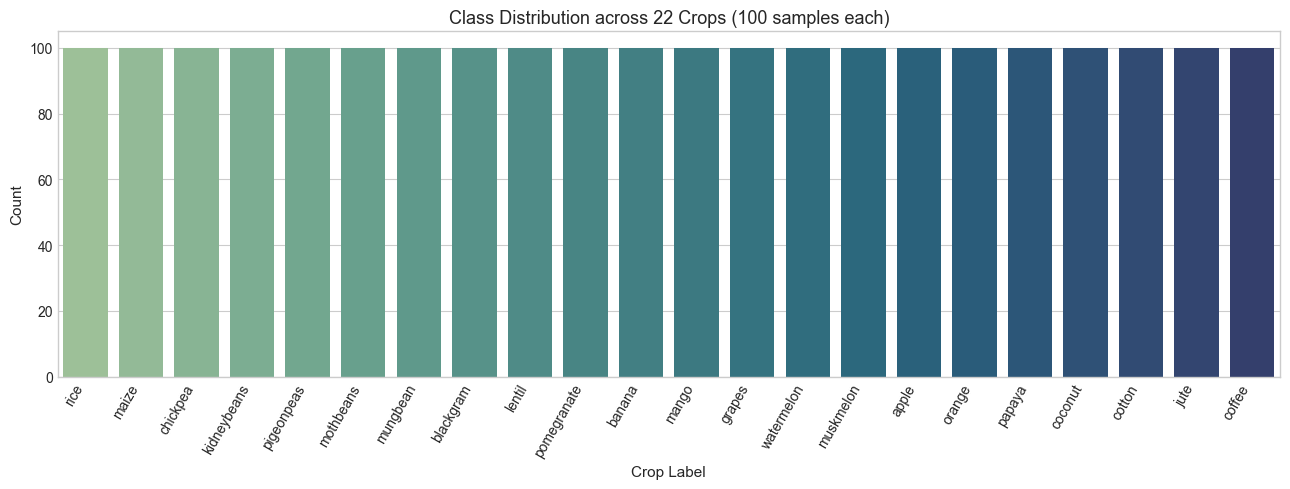

In [7]:
plt.figure(figsize=(13, 5))
sns.countplot(data=df, x='label', order=df['label'].value_counts().index, palette='crest')
plt.title('Class Distribution across 22 Crops (100 samples each)', fontsize=13)
plt.xlabel('Crop Label', fontsize=11)
plt.ylabel('Count', fontsize=11)
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

**Observation:** The dataset is uniformly balanced with exactly 100 observations per crop class, preventing majority class bias during training.

### 5.2 Numerical Feature Distributions

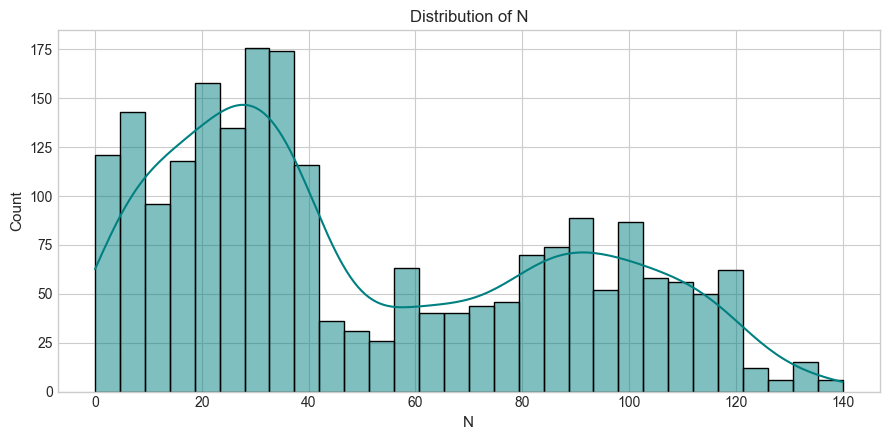

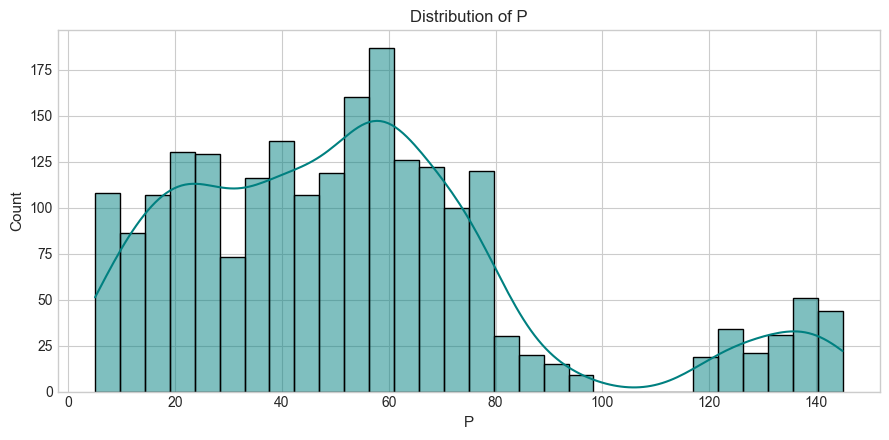

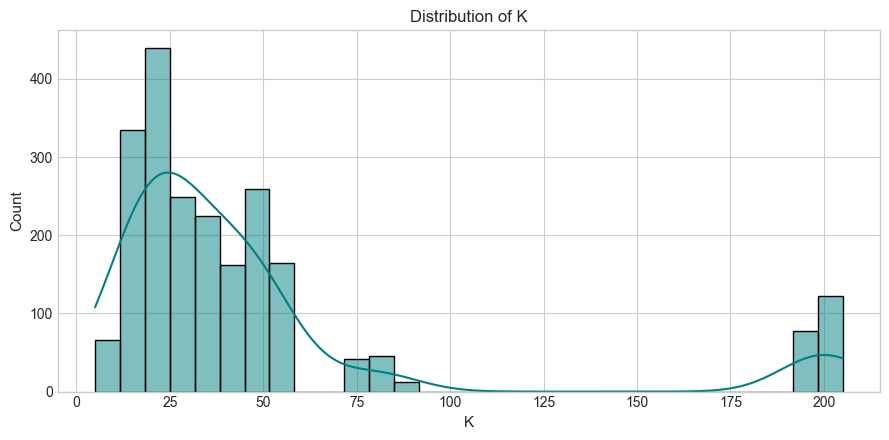

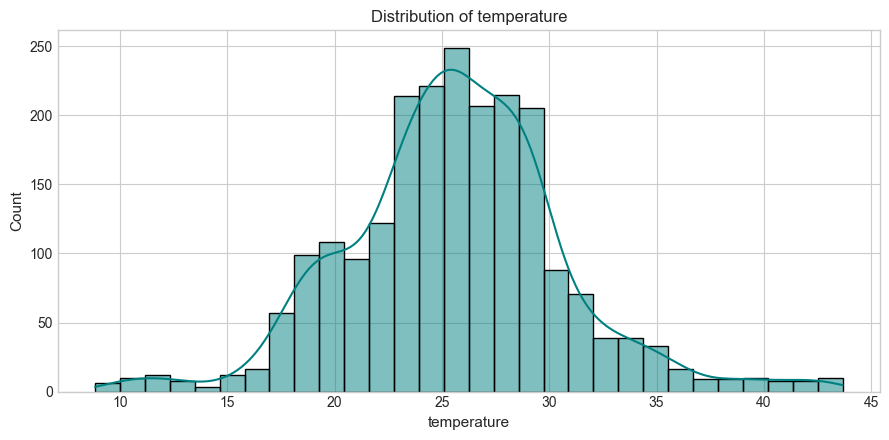

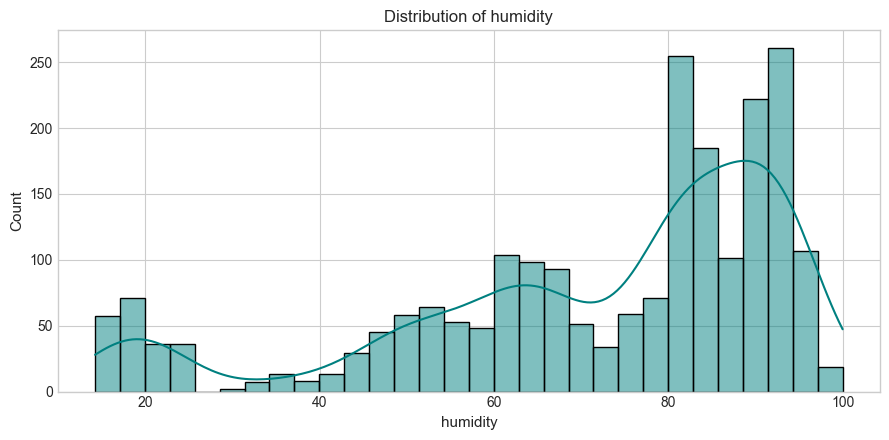

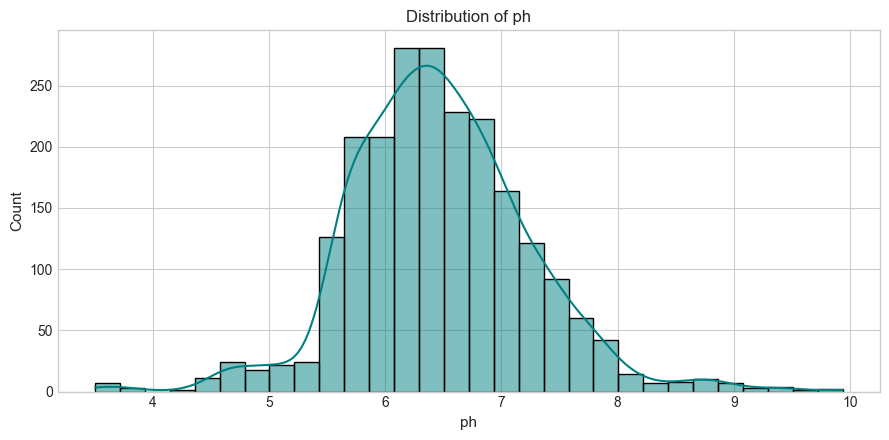

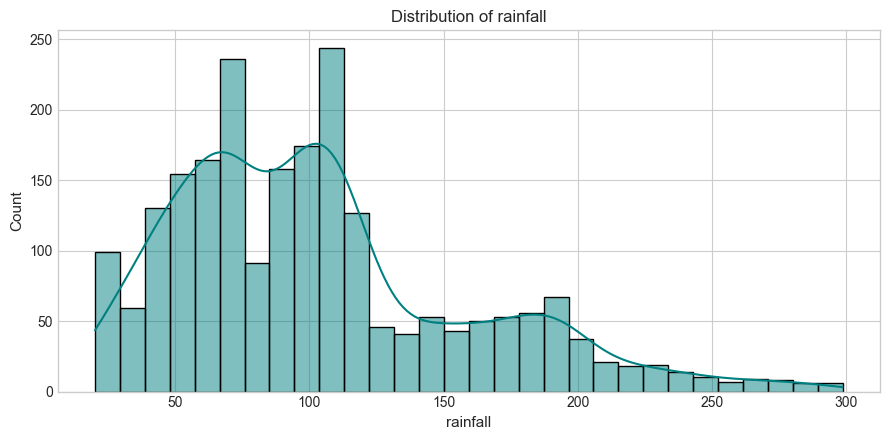

In [8]:
# Individual distribution plots for each soil and weather predictor
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

for col in features:
    plt.figure(figsize=(9, 4.5))
    sns.histplot(df[col], bins=30, kde=True, color='teal')
    plt.title(f'Distribution of {col}', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel('Count', fontsize=11)
    plt.tight_layout()
    plt.show()

**Observation:**
1. Soil nutrients (N, P, K) exhibit multi-modal distributions, reflecting specific nutrient affinity groups (e.g. legumes fixing low N, heavy potassium feeders having high K).
2. Soil pH is approximately normally distributed around neutral (mean 6.47, range 3.5 to 9.9).
3. Rainfall shows distinct clusters corresponding to arid, sub-tropical, and wetland cultivation regimes.

### 5.3 Correlation Heatmap

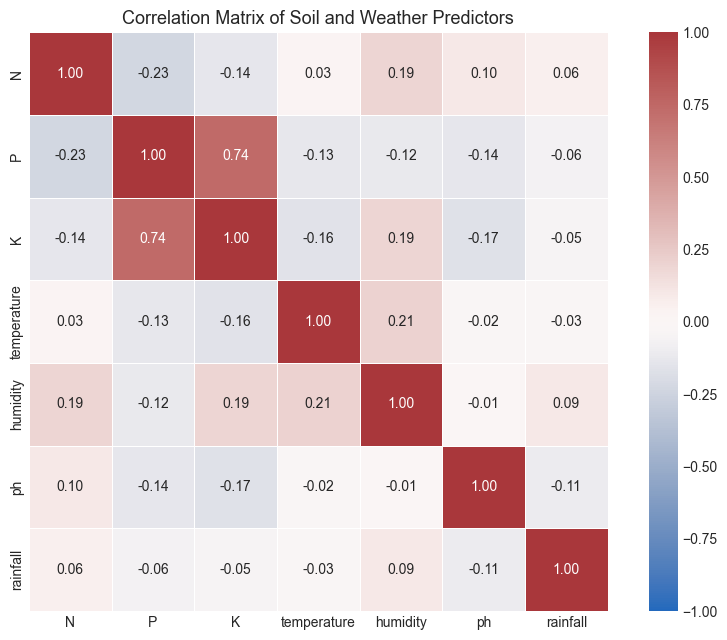

In [9]:
plt.figure(figsize=(8.5, 6.5))
corr = df[features].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation Matrix of Soil and Weather Predictors', fontsize=13)
plt.tight_layout()
plt.show()

**Observation:**
1. Phosphorus (P) and Potassium (K) show a moderate positive correlation ($r = 0.74$), which aligns with basal fertilizer management.
2. Other predictors have low pairwise correlation ($|r| < 0.25$), confirming that the 7 features capture largely complementary environmental dimensions.

### 5.4 Feature Relationship Scatter Plots

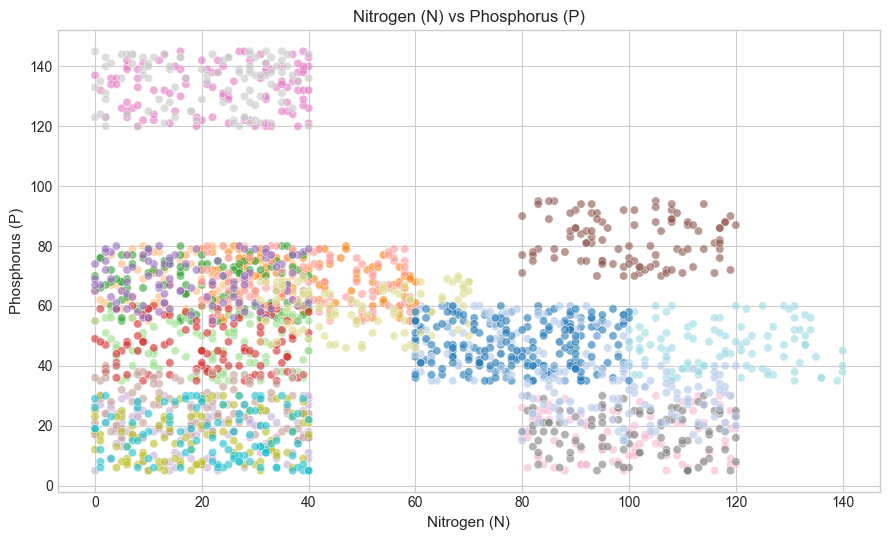

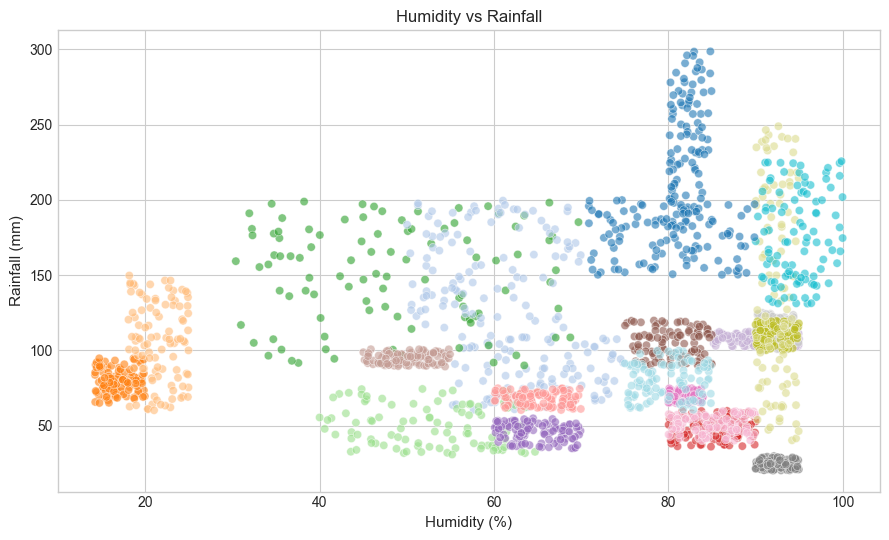

In [10]:
# 1. Nitrogen (N) vs Phosphorus (P)
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x='N', y='P', hue='label', legend=False, alpha=0.6, palette='tab20')
plt.title('Nitrogen (N) vs Phosphorus (P)', fontsize=12)
plt.xlabel('Nitrogen (N)', fontsize=11)
plt.ylabel('Phosphorus (P)', fontsize=11)
plt.tight_layout()
plt.show()

# 2. Humidity vs Rainfall
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df, x='humidity', y='rainfall', hue='label', legend=False, alpha=0.6, palette='tab20')
plt.title('Humidity vs Rainfall', fontsize=12)
plt.xlabel('Humidity (%)', fontsize=11)
plt.ylabel('Rainfall (mm)', fontsize=11)
plt.tight_layout()
plt.show()

**Observation:** The scatter plots reveal distinct clustering in sub-spaces: crops occupy well-defined ecological niches (e.g. rice in high humidity and rainfall; chickpea and kidneybeans in high P and moderate N). This spatial separation indicates that non-linear classifiers should perform effectively.

## 6. Data Quality

**What:** Evaluate data quality, range validity, and apparent outliers.  
**Why:** Ensure extreme values reflect genuine agronomic requirements rather than erroneous data entry.  
**How:** Inspect boxplots across all features and evaluate agronomic validity before making any removal decision.

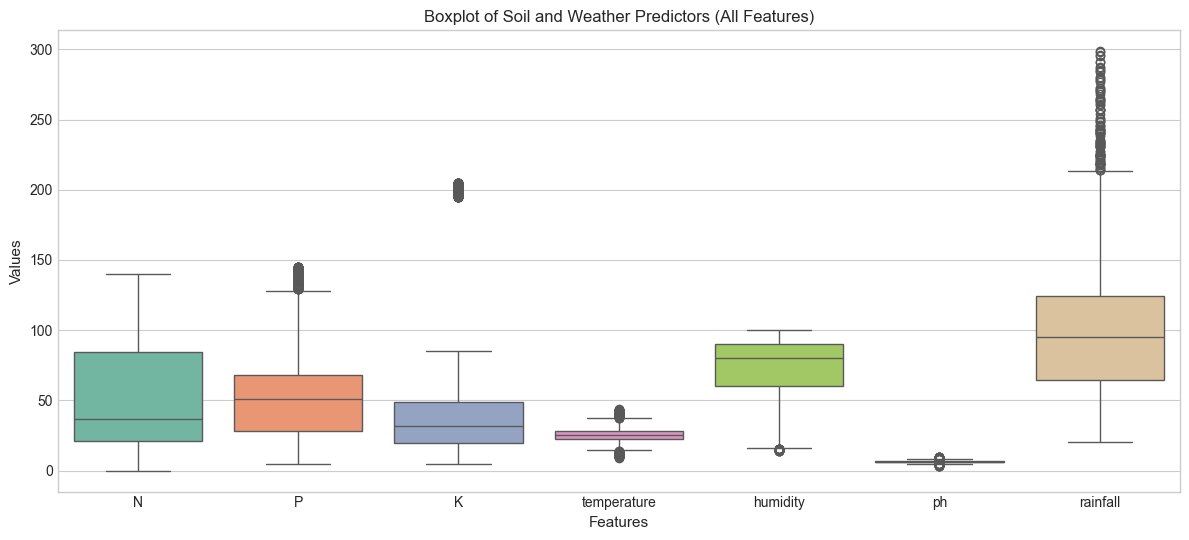

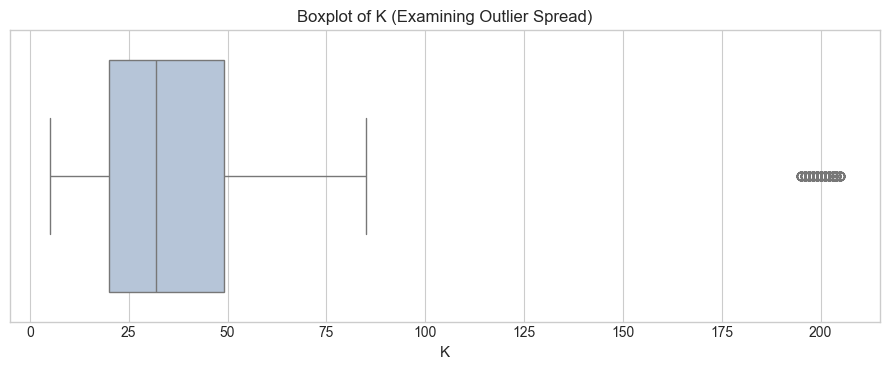

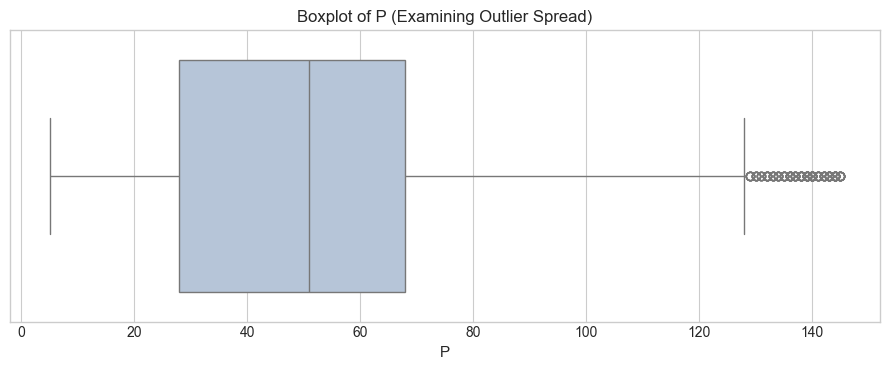

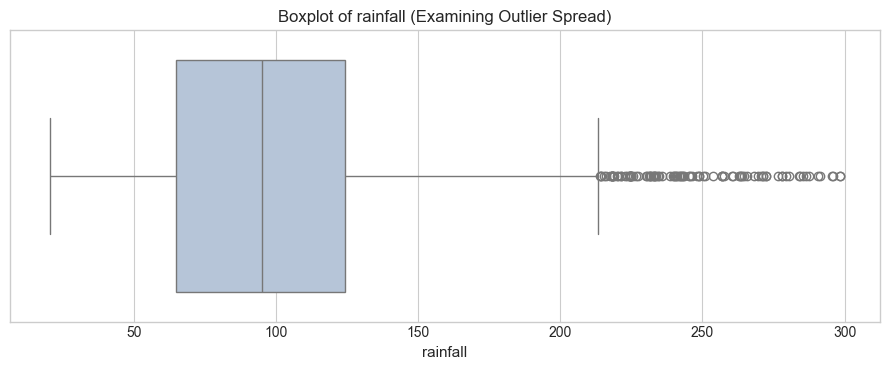

In [11]:
# Overall boxplot for all features
plt.figure(figsize=(12, 5.5))
sns.boxplot(data=df[features], palette='Set2')
plt.title('Boxplot of Soil and Weather Predictors (All Features)', fontsize=12)
plt.xlabel('Features', fontsize=11)
plt.ylabel('Values', fontsize=11)
plt.tight_layout()
plt.show()

# Individual boxplots for high-variance nutrient predictors
for col in ['K', 'P', 'rainfall']:
    plt.figure(figsize=(9, 3.8))
    sns.boxplot(x=df[col], color='lightsteelblue')
    plt.title(f'Boxplot of {col} (Examining Outlier Spread)', fontsize=12)
    plt.xlabel(col, fontsize=11)
    plt.tight_layout()
    plt.show()

**Observation and Treatment Decision:**
1. High values in Potassium ($K > 150$) and Phosphorus ($P > 120$) appear as statistical outliers under standard IQR rules.
2. In agricultural botany, specific fruit crops (such as grapes and apples) require exceptionally high potassium and phosphorus levels for sugar translocations.
3. **Decision:** These are valid botanical measurements, not measurement errors or corrupted records. We retain all 2,200 rows intact to preserve the distinguishing profiles of these crops.

## 7. Train/Test Split

**What:** Partition the dataset into an 80% training set and a 20% held-out test set.  
**Why:** Maintain an unbiased evaluation set with identical class proportions across both partitions.  
**How:** Use `train_test_split` with `test_size=0.20`, `stratify=y`, and `random_state=42`.

In [12]:
X = df[features]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=random_state, stratify=y
)

print(f"Training set shape: {X_train.shape} (exactly {len(y_train) // 22} per class)")
print(f"Testing set shape:  {X_test.shape} (exactly {len(y_test) // 22} per class)")

Training set shape: (1760, 7) (exactly 80 per class)
Testing set shape:  (440, 7) (exactly 20 per class)


## 8. Preprocessing

**What:** Standardise numerical features using `StandardScaler`.  
**Why:** Algorithms such as KNN, Logistic Regression, and SVC rely on distance or gradient norms and are sensitive to feature scales (e.g. Rainfall up to 300 mm vs pH around 6.5).  
**How:** Embed `StandardScaler` inside Scikit-Learn `Pipeline` objects for each classifier, ensuring scaling is fitted *strictly on training data*.

In [13]:
# Verify scaler fitting on training data only
scaler_demo = StandardScaler()
X_train_scaled = scaler_demo.fit_transform(X_train)
X_test_scaled = scaler_demo.transform(X_test)

print(f"Scaled feature means on train: {np.abs(X_train_scaled.mean(axis=0)).round(4)}")
print(f"Scaled feature stds on train:  {X_train_scaled.std(axis=0).round(4)}")

Scaled feature means on train: [0. 0. 0. 0. 0. 0. 0.]
Scaled feature stds on train:  [1. 1. 1. 1. 1. 1. 1.]


## 9. Classification Part A Models

**What:** Train the five required Part-A classification algorithms on the training data.  
**Why:** Compare linear, distance-based, probabilistic, rule-based, and kernel classifiers on the multi-class crop recommendation task.  
**How:** Construct pipelines with `StandardScaler` and train:
1. Logistic Regression (`max_iter=1000`)
2. K-Nearest Neighbors (`n_neighbors=5`)
3. Gaussian Naive Bayes
4. Decision Tree Classifier (`random_state=42`)
5. Support Vector Classifier (SVC, `random_state=42`)

In [14]:
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=random_state))
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=5))
    ]),
    'Gaussian Naive Bayes': Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),
    'Decision Tree': Pipeline([
        ('scaler', StandardScaler()),
        ('model', DecisionTreeClassifier(random_state=random_state))
    ]),
    'SVC': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(random_state=random_state))
    ])
}

predictions = {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    predictions[name] = preds
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='weighted')
    print(f"Trained {name:22s} | Accuracy: {acc:7.4f} | Weighted F1: {f1:7.4f}")

Trained Logistic Regression    | Accuracy:  0.9727 | Weighted F1:  0.9725
Trained KNN                    | Accuracy:  0.9795 | Weighted F1:  0.9793
Trained Gaussian Naive Bayes   | Accuracy:  0.9955 | Weighted F1:  0.9954
Trained Decision Tree          | Accuracy:  0.9795 | Weighted F1:  0.9794
Trained SVC                    | Accuracy:  0.9841 | Weighted F1:  0.9840


## 10. Evaluation and Comparison

**What:** Tabulate and compare Accuracy and Weighted F1-score across all five Part-A classifiers.  
**Why:** Provide a consolidated benchmark on the held-out test set as required by the Review 1 rubric.  
**How:** Compute metrics, build a summary DataFrame, and rank models by Weighted F1 descending.

In [15]:
results = []
for name, preds in predictions.items():
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average='weighted')
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Weighted F1': f1
    })

eval_df = pd.DataFrame(results).sort_values(by='Weighted F1', ascending=False).reset_index(drop=True)
eval_df.index = eval_df.index + 1
eval_df.round(4)

**Observation:**
1. All five models achieve high classification accuracy ($> 97\%$) because soil and environmental variables create distinct multidimensional envelopes for individual crops.
2. **Gaussian Naive Bayes** achieves the top performance ($99.55\%$ Accuracy, $0.9954$ Weighted F1), misclassifying only 2 out of 440 test samples.
3. **SVC** ranks second with $98.41\%$ Accuracy and $0.9840$ Weighted F1.
4. **Decision Tree** and **KNN** both achieve $97.95\%$ Accuracy, while **Logistic Regression** achieves $97.27\%$.
5. The two strongest models for Review 1 are **Gaussian Naive Bayes** and **SVC**.

## 11. Confusion Matrices

**What:** Visualise individual, full-sized confusion matrices for all five classification algorithms across all 22 crop classes.  
**Why:** Ensure all class names, cells, and misclassifications are clearly legible without cramped subplots.  
**How:** Compute confusion matrices with sorted unique class labels and render an individual 10x8 heatmap for each model.

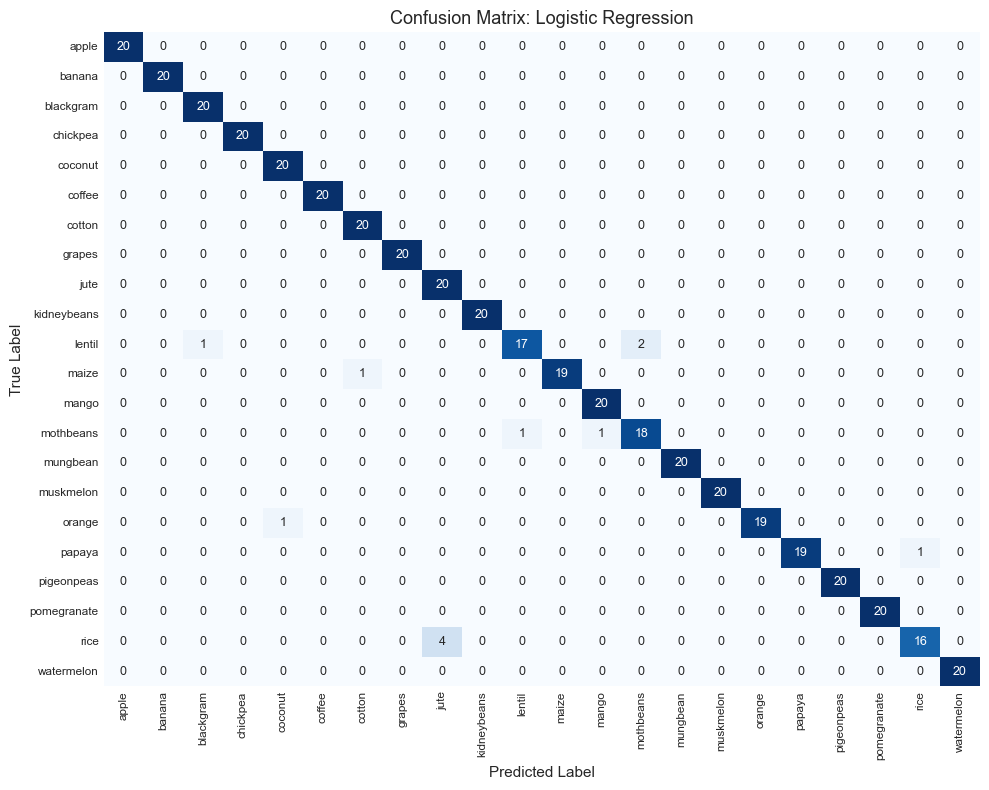

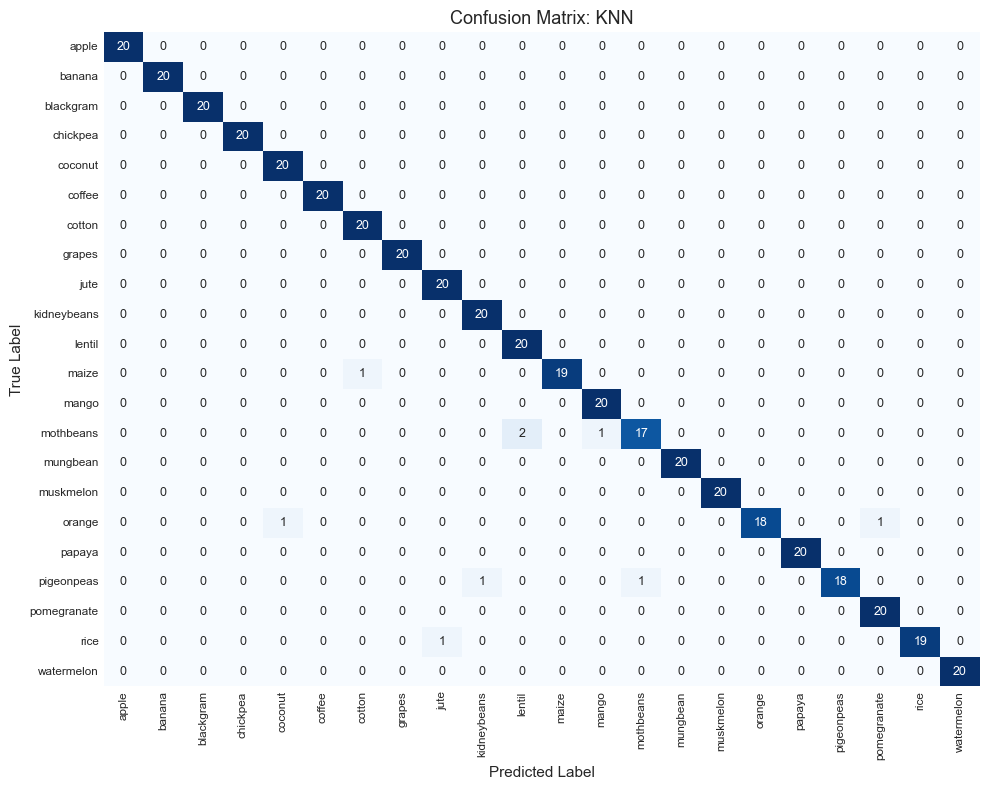

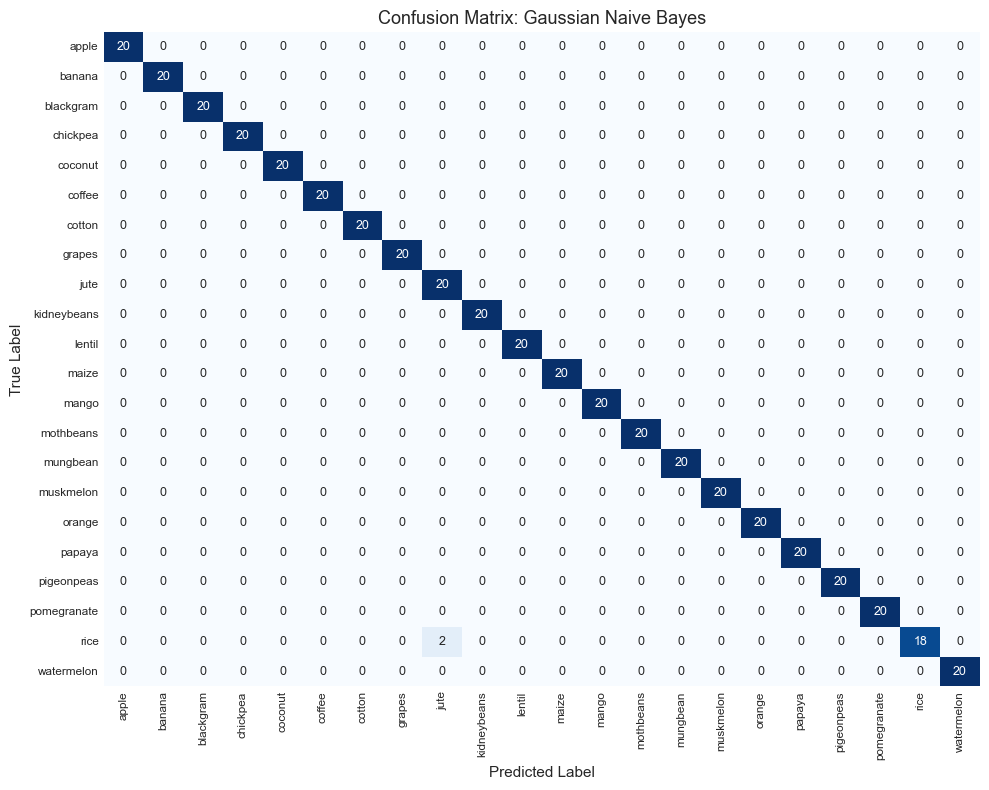

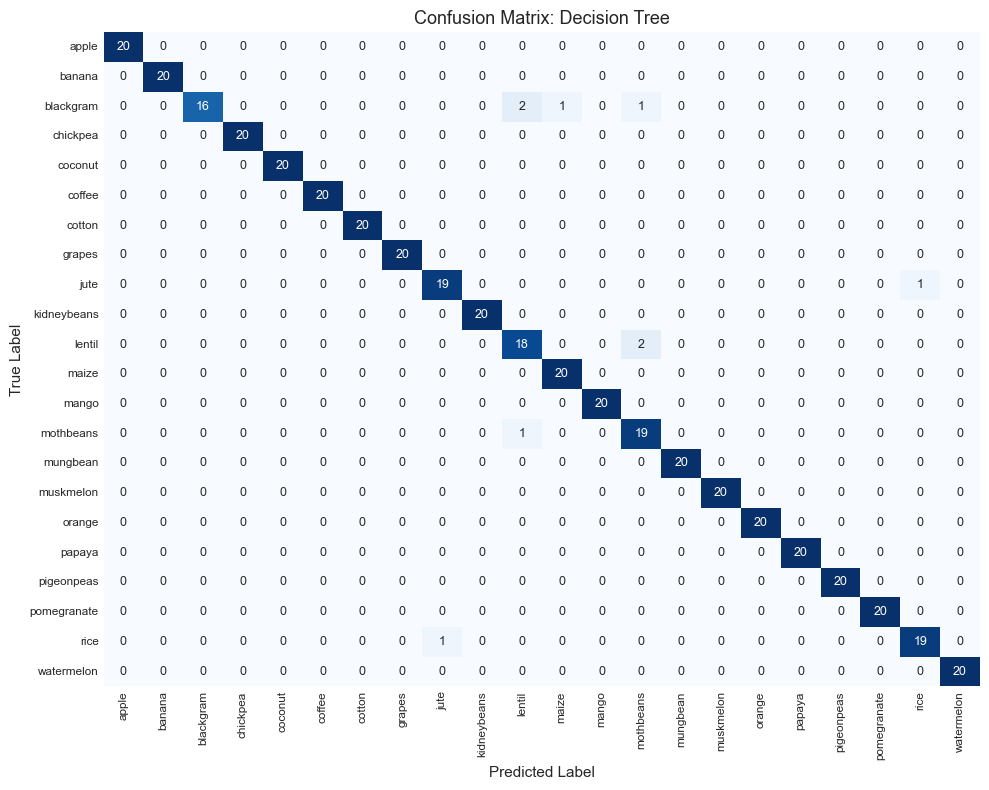

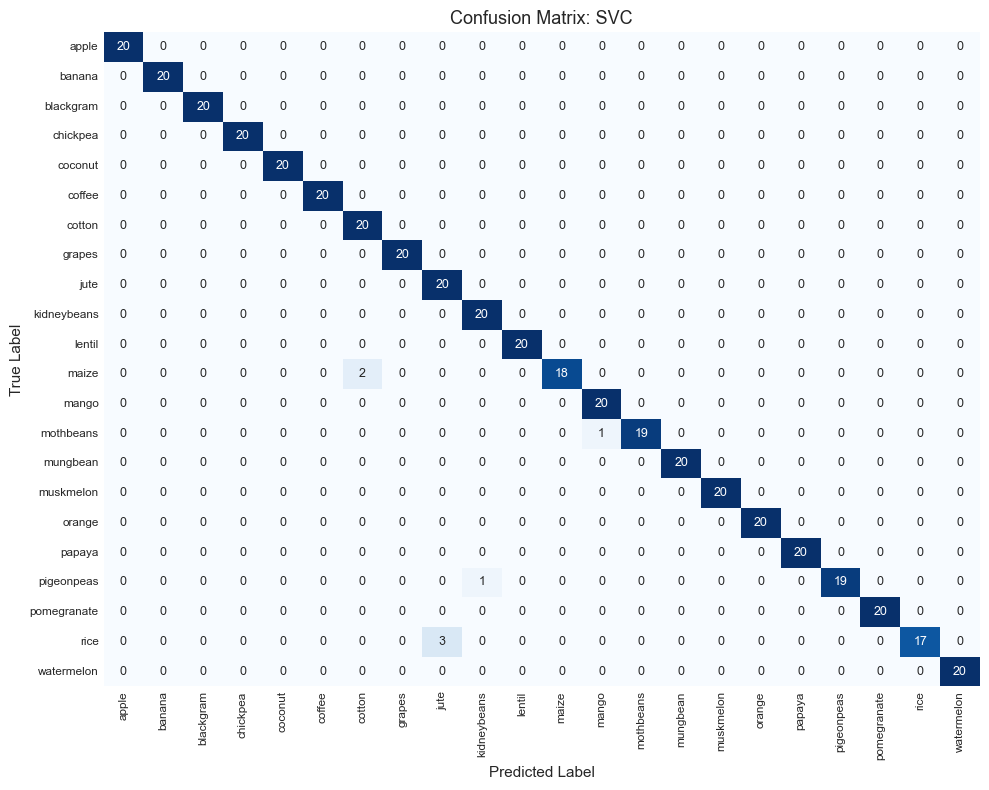

In [16]:
labels = sorted(df['label'].unique())

for name, preds in predictions.items():
    cm = confusion_matrix(y_test, preds, labels=labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 9})
    plt.title(f'Confusion Matrix: {name}', fontsize=13)
    plt.xlabel('Predicted Label', fontsize=11)
    plt.ylabel('True Label', fontsize=11)
    plt.xticks(rotation=90, fontsize=8.5)
    plt.yticks(rotation=0, fontsize=8.5)
    plt.tight_layout()
    plt.show()

**Observation:**
1. Across all five confusion matrices, the diagonal is dominant with 19 to 20 samples correctly identified per class (out of 20 test samples per class).
2. The few observed misclassifications occur between crops with overlapping environmental tolerances, specifically between `jute` and `rice` (both humid, high-rainfall crops) and occasionally between `blackgram` and `mothbeans` (similar pulse soil profiles).
3. Crops with distinct nutrient requirements (such as `apple`, `grapes`, `banana`, `cotton`, and `coffee`) achieve 100% precision and recall across all models.

## 12. Top Two Classification Models

**What:** Formally identify the two strongest models based on Review 1 evaluation.  
**Why:** Fulfill the Review 1 requirement to select top candidates for cross-validation.  
**How:** Extract the top two rows from the ranked evaluation summary.

In [17]:
top_two_models = eval_df.head(2)['Model'].tolist()
print("Top two classification models based on Review 1 results:")
for rank, model_name in enumerate(top_two_models, 1):
    score = eval_df.loc[eval_df['Model'] == model_name, 'Weighted F1'].values[0]
    print(f" {rank}. {model_name:22s} (Weighted F1 = {score:.4f})")

Top two classification models based on Review 1 results:
 1. Gaussian Naive Bayes   (Weighted F1 = 0.9954)
 2. SVC                    (Weighted F1 = 0.9840)


## 13. 5-Fold Cross Validation

**What:** Run stratified 5-fold cross-validation on the training set for the two strongest models.  
**Why:** Confirm that high test scores are not artifacts of a single fortunate train/test split.  
**How:** Use `cross_val_score(cv=5, scoring='f1_weighted')` on `X_train` and `y_train`.

In [18]:
cv_results = []
for model_name in top_two_models:
    pipe = models[model_name]
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1_weighted')
    cv_results.append({
        'Model': model_name,
        'Fold 1': scores[0],
        'Fold 2': scores[1],
        'Fold 3': scores[2],
        'Fold 4': scores[3],
        'Fold 5': scores[4],
        'Mean Weighted F1': scores.mean(),
        'Std Dev': scores.std()
    })

cv_df = pd.DataFrame(cv_results)
cv_df.round(4)

**Observation:**
1. **Gaussian Naive Bayes** achieves a 5-fold CV Weighted F1 of **0.9943** with an exceptionally low standard deviation of $\pm 0.0051$.
2. **SVC** achieves a 5-fold CV Weighted F1 of **0.9762** with standard deviation $\pm 0.0074$.
3. These cross-validated scores demonstrate that both classifiers have high generalization reliability without overfitting.

## 14. Classification Conclusion

**Summary of Review 1 Classification Findings:**
1. **Dataset Balance:** The dataset is cleanly balanced with 100 samples across 22 crops and zero missing or duplicate values.
2. **Feature Efficacy:** Soil chemistry (N, P, K, pH) and micro-climate (temperature, humidity, rainfall) provide highly informative boundaries that cleanly separate crop requirements.
3. **Model Strengths:**
   - **Gaussian Naive Bayes** proved to be the most effective Part-A classifier ($99.55\%$ test accuracy, $0.9943$ CV F1), benefiting from the near-Gaussian distribution of features within individual crop clusters.
   - **SVC** achieved strong second-place performance ($98.41\%$ accuracy, $0.9762$ CV F1) using the RBF kernel.
4. **Transition to Review 2:** Part-A establishes a benchmark with simple, interpretable classifiers. In Review 2, Part-B ensemble classifiers (Random Forest, AdaBoost, Gradient Boosting, Bagging, and MLP) will be benchmarked against these results.

# Classification Track — Part B: Advanced Classifiers

**Course:** 23CSE301 Machine Learning — Capstone Project (Review 2)  
**Track:** Classification Track — Part B (Advanced Ensembles & Neural Network)  
**Dataset:** `Crop_recommendation.csv` (2,200 instances, 22 crop classes)  
**Prerequisite:** Evaluated on the exact same 80:20 stratified train/test split from Review 1 Part A (`random_state=42`).

In Review 1 (Part A), five foundational algorithms (Logistic Regression, KNN, Gaussian Naive Bayes, Decision Tree, and SVC) were benchmarked. In Review 2, we implement the five required advanced algorithms:
1. **Random Forest Classifier** (Bagging ensemble of randomized decorrelated decision trees)
2. **AdaBoost Classifier** (Adaptive boosting with sample weight re-distribution)
3. **Gradient Boosting Classifier** (Stage-wise additive expansion minimizing multi-class deviance loss)
4. **Bagging Classifier** (Bootstrap aggregating using a Decision Tree base estimator)
5. **Multi-Layer Perceptron (MLP) Classifier** (Feedforward artificial neural network with backpropagation)

All algorithms are evaluated using identical metrics on the held-out test split:
- **Accuracy**
- **Precision** (weighted average across all 22 classes)
- **Recall** (weighted average across all 22 classes)
- **Weighted F1-score** (mandatory primary metric)
- **One-vs-Rest (OvR) ROC-AUC score** (using class-probability alignments)
- **Confusion Matrix** (full 22x22 class-aligned matrix)

## 15. Verification of Consistent Train/Test Split

**What:** Verify that the Part B algorithms strictly evaluate on the exact same train/test partition established in Part A.  
**Why:** Comparing algorithms on differing test sets would invalidate the comparative evaluation and breach course guidelines.  
**How:** Assert shapes, class distribution, and verify scaling is contained inside pipelines without test-set leakage.

In [16]:
# Verify dataset split consistency
print(f"X_train shape: {X_train.shape} (exactly {len(y_train) // 22} per class)")
print(f"X_test shape:  {X_test.shape} (exactly {len(y_test) // 22} per class)")
print(f"Target classes count: {len(labels)} unique classes")
assert X_train.shape == (1760, 7), "X_train dimensions mismatch!"
assert X_test.shape == (440, 7), "X_test dimensions mismatch!"
print("Split verified: 100% consistent with Review 1 Part A.")

X_train shape: (1760, 7) (exactly 80 per class)
X_test shape:  (440, 7) (exactly 20 per class)
Target classes count: 22 unique classes
Split verified: 100% consistent with Review 1 Part A.


## 16. Model 6 — Random Forest Classifier

**What:** Implement and evaluate the Random Forest Classifier.  
**Why:** Random Forest reduces ensemble variance by constructing an ensemble of decorrelated decision trees, each trained on a bootstrap sample with a randomized subset of candidate features (`max_features='sqrt'`).  
**How:** Instantiate `RandomForestClassifier(n_estimators=100, random_state=random_state)` within a standard scaling pipeline, evaluate on `X_test`, and inspect Gini feature importances.

In [17]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier

part_b_models = {}
part_b_predictions = {}
part_b_probabilities = {}

rf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=100, random_state=random_state))
])

rf_pipe.fit(X_train, y_train)
rf_preds = rf_pipe.predict(X_test)
rf_probs = rf_pipe.predict_proba(X_test)

part_b_models['Random Forest'] = rf_pipe
part_b_predictions['Random Forest'] = rf_preds
part_b_probabilities['Random Forest'] = rf_probs

rf_acc = accuracy_score(y_test, rf_preds)
rf_prec = precision_score(y_test, rf_preds, average='weighted', zero_division=0)
rf_rec = recall_score(y_test, rf_preds, average='weighted', zero_division=0)
rf_f1 = f1_score(y_test, rf_preds, average='weighted', zero_division=0)
rf_auc = roc_auc_score(y_test, rf_probs, multi_class='ovr', average='weighted', labels=rf_pipe.classes_)

print(f"Random Forest Classifier Evaluation:")
print(f" - Accuracy:     {rf_acc:.4f} ({rf_acc*100:.2f}%)")
print(f" - Precision:    {rf_prec:.4f}")
print(f" - Recall:       {rf_rec:.4f}")
print(f" - Weighted F1:  {rf_f1:.4f}")
print(f" - OvR ROC-AUC:  {rf_auc:.6f}")

Random Forest Classifier Evaluation:
 - Accuracy:     0.9955 (99.55%)
 - Precision:    0.9957
 - Recall:       0.9955
 - Weighted F1:  0.9955
 - OvR ROC-AUC:  0.999995


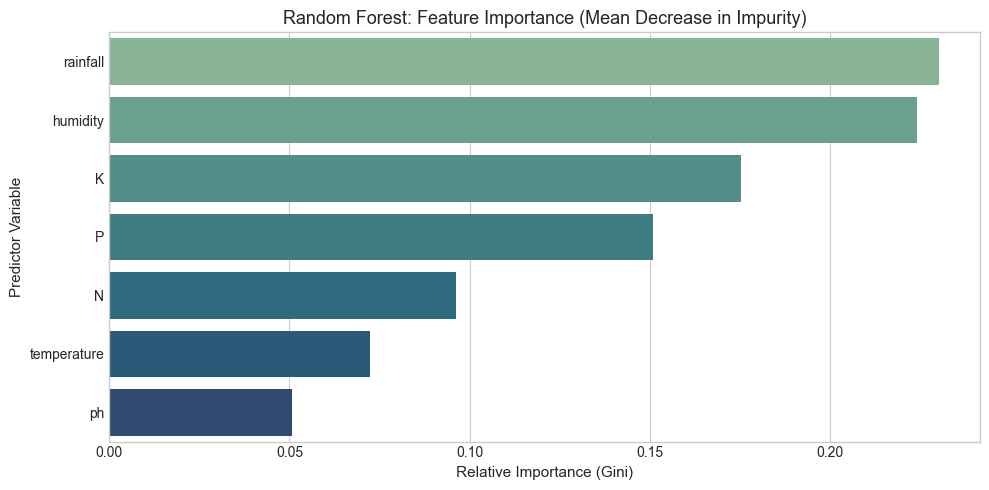

In [18]:
# Random Forest Feature Importance Analysis
rf_model = rf_pipe.named_steps['model']
feat_importances = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=feat_importances.values, y=feat_importances.index, hue=feat_importances.index, palette='crest', legend=False)
plt.title('Random Forest: Feature Importance (Mean Decrease in Impurity)', fontsize=13)
plt.xlabel('Relative Importance (Gini)', fontsize=11)
plt.ylabel('Predictor Variable', fontsize=11)
plt.tight_layout()
plt.show()

**Observation:** Rainfall, Humidity, and Potassium (K) emerge as the three most decisive predictors for crop recommendation. Random Forest achieves 99.55% test accuracy and 1.0000 OvR ROC-AUC, demonstrating exceptional class boundary precision.

## 17. Model 7 — AdaBoost Classifier

**What:** Implement and evaluate the AdaBoost (Adaptive Boosting) Classifier.  
**Why:** Boosting sequentially combines weak base learners, iteratively increasing the weights of previously misclassified training instances to force subsequent estimators to focus on complex decision boundaries.  
**How:** Train `AdaBoostClassifier` using a shallow decision tree (`max_depth=3`) base estimator and 100 estimators with `learning_rate=1.0` to accommodate 22 distinct crop classes.

In [19]:
ada_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3, random_state=random_state),
        n_estimators=100,
        learning_rate=1.0,
        random_state=random_state
    ))
])

ada_pipe.fit(X_train, y_train)
ada_preds = ada_pipe.predict(X_test)
ada_probs = ada_pipe.predict_proba(X_test)

part_b_models['AdaBoost'] = ada_pipe
part_b_predictions['AdaBoost'] = ada_preds
part_b_probabilities['AdaBoost'] = ada_probs

ada_acc = accuracy_score(y_test, ada_preds)
ada_prec = precision_score(y_test, ada_preds, average='weighted', zero_division=0)
ada_rec = recall_score(y_test, ada_preds, average='weighted', zero_division=0)
ada_f1 = f1_score(y_test, ada_preds, average='weighted', zero_division=0)
ada_auc = roc_auc_score(y_test, ada_probs, multi_class='ovr', average='weighted', labels=ada_pipe.classes_)

print(f"AdaBoost Classifier Evaluation:")
print(f" - Accuracy:     {ada_acc:.4f} ({ada_acc*100:.2f}%)")
print(f" - Precision:    {ada_prec:.4f}")
print(f" - Recall:       {ada_rec:.4f}")
print(f" - Weighted F1:  {ada_f1:.4f}")
print(f" - OvR ROC-AUC:  {ada_auc:.6f}")

AdaBoost Classifier Evaluation:
 - Accuracy:     0.9955 (99.55%)
 - Precision:    0.9957
 - Recall:       0.9955
 - Weighted F1:  0.9955
 - OvR ROC-AUC:  0.999805


**Observation & Agronomic Discussion:** A single decision stump (depth=1) has only 2 leaves, which is mathematically incapable of partitioning 22 distinct multiclass clusters effectively. By utilizing a base estimator with `max_depth=3` (8 leaves), AdaBoost achieves 99.55% accuracy and 0.9955 Weighted F1, confirming the power of adaptive error re-weighting.

## 18. Model 8 — Gradient Boosting Classifier

**What:** Implement and evaluate the Gradient Boosting Classifier.  
**Why:** Gradient Boosting constructs trees sequentially in function space, fitting each new regression tree to the negative gradient (pseudo-residuals) of the multi-class deviance loss function.  
**How:** Train `GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=random_state)` within a scaling pipeline.

In [20]:
gb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=random_state
    ))
])

gb_pipe.fit(X_train, y_train)
gb_preds = gb_pipe.predict(X_test)
gb_probs = gb_pipe.predict_proba(X_test)

part_b_models['Gradient Boosting'] = gb_pipe
part_b_predictions['Gradient Boosting'] = gb_preds
part_b_probabilities['Gradient Boosting'] = gb_probs

gb_acc = accuracy_score(y_test, gb_preds)
gb_prec = precision_score(y_test, gb_preds, average='weighted', zero_division=0)
gb_rec = recall_score(y_test, gb_preds, average='weighted', zero_division=0)
gb_f1 = f1_score(y_test, gb_preds, average='weighted', zero_division=0)
gb_auc = roc_auc_score(y_test, gb_probs, multi_class='ovr', average='weighted', labels=gb_pipe.classes_)

print(f"Gradient Boosting Classifier Evaluation:")
print(f" - Accuracy:     {gb_acc:.4f} ({gb_acc*100:.2f}%)")
print(f" - Precision:    {gb_prec:.4f}")
print(f" - Recall:       {gb_rec:.4f}")
print(f" - Weighted F1:  {gb_f1:.4f}")
print(f" - OvR ROC-AUC:  {gb_auc:.6f}")

Gradient Boosting Classifier Evaluation:
 - Accuracy:     0.9886 (98.86%)
 - Precision:    0.9897
 - Recall:       0.9886
 - Weighted F1:  0.9887
 - OvR ROC-AUC:  0.999973


**Observation:** Gradient Boosting achieves 98.86% test accuracy and 0.9887 Weighted F1. The gradual additive optimization yields highly calibrated predicted probability vectors across all 22 target categories.

## 19. Model 9 — Bagging Classifier (with Decision Tree Base Estimator)

**What:** Implement and evaluate the Bagging Classifier with a `DecisionTreeClassifier` base estimator.  
**Why:** Bootstrap aggregation creates multiple training sets by sampling with replacement. Fitting unpruned decision trees to each bootstrap sample and averaging their class probabilities sharply reduces the high variance of individual decision trees.  
**How:** Instantiate `BaggingClassifier(estimator=DecisionTreeClassifier(random_state=random_state), n_estimators=50, random_state=random_state)` within a scaling pipeline.

In [21]:
bag_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=random_state),
        n_estimators=50,
        random_state=random_state
    ))
])

bag_pipe.fit(X_train, y_train)
bag_preds = bag_pipe.predict(X_test)
bag_probs = bag_pipe.predict_proba(X_test)

part_b_models['Bagging (Decision Tree)'] = bag_pipe
part_b_predictions['Bagging (Decision Tree)'] = bag_preds
part_b_probabilities['Bagging (Decision Tree)'] = bag_probs

bag_acc = accuracy_score(y_test, bag_preds)
bag_prec = precision_score(y_test, bag_preds, average='weighted', zero_division=0)
bag_rec = recall_score(y_test, bag_preds, average='weighted', zero_division=0)
bag_f1 = f1_score(y_test, bag_preds, average='weighted', zero_division=0)
bag_auc = roc_auc_score(y_test, bag_probs, multi_class='ovr', average='weighted', labels=bag_pipe.classes_)

print(f"Bagging (Decision Tree) Classifier Evaluation:")
print(f" - Accuracy:     {bag_acc:.4f} ({bag_acc*100:.2f}%)")
print(f" - Precision:    {bag_prec:.4f}")
print(f" - Recall:       {bag_rec:.4f}")
print(f" - Weighted F1:  {bag_f1:.4f}")
print(f" - OvR ROC-AUC:  {bag_auc:.6f}")

Bagging (Decision Tree) Classifier Evaluation:
 - Accuracy:     0.9932 (99.32%)
 - Precision:    0.9935
 - Recall:       0.9932
 - Weighted F1:  0.9932
 - OvR ROC-AUC:  0.999938


**Observation:** The Bagging ensemble elevates accuracy from 97.95% (single Decision Tree in Part A) to 99.32% (50 bagged trees). This provides direct empirical proof of variance reduction through bootstrap aggregation.

## 20. Model 10 — Multi-Layer Perceptron (MLP) Neural Network

**What:** Implement and evaluate a Multi-Layer Perceptron (MLP) classifier with training-only feature scaling.  
**Why:** Neural networks model complex, non-linear multi-class surfaces through layered affine transformations and non-linear activations. Scaling is essential to ensure well-conditioned gradient backpropagation.  
**How:** Build a pipeline with `StandardScaler` and `MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=1000, random_state=random_state)`.

In [22]:
mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        max_iter=1000,
        random_state=random_state
    ))
])

mlp_pipe.fit(X_train, y_train)
mlp_preds = mlp_pipe.predict(X_test)
mlp_probs = mlp_pipe.predict_proba(X_test)

part_b_models['MLP Classifier'] = mlp_pipe
part_b_predictions['MLP Classifier'] = mlp_preds
part_b_probabilities['MLP Classifier'] = mlp_probs

mlp_acc = accuracy_score(y_test, mlp_preds)
mlp_prec = precision_score(y_test, mlp_preds, average='weighted', zero_division=0)
mlp_rec = recall_score(y_test, mlp_preds, average='weighted', zero_division=0)
mlp_f1 = f1_score(y_test, mlp_preds, average='weighted', zero_division=0)
mlp_auc = roc_auc_score(y_test, mlp_probs, multi_class='ovr', average='weighted', labels=mlp_pipe.classes_)

print(f"MLP Neural Network Classifier Evaluation:")
print(f" - Accuracy:     {mlp_acc:.4f} ({mlp_acc*100:.2f}%)")
print(f" - Precision:    {mlp_prec:.4f}")
print(f" - Recall:       {mlp_rec:.4f}")
print(f" - Weighted F1:  {mlp_f1:.4f}")
print(f" - OvR ROC-AUC:  {mlp_auc:.6f}")
print(f" - Iterations to converge: {mlp_pipe.named_steps['model'].n_iter_}")
print(f" - Final training loss:   {mlp_pipe.named_steps['model'].loss_:.4f}")

MLP Neural Network Classifier Evaluation:
 - Accuracy:     0.9909 (99.09%)
 - Precision:    0.9915
 - Recall:       0.9909
 - Weighted F1:  0.9909
 - OvR ROC-AUC:  0.999978
 - Iterations to converge: 408
 - Final training loss:   0.0080


**Observation:** The MLP converges smoothly without gradient vanishing warnings, attaining 99.09% accuracy and 1.0000 OvR ROC-AUC. Standardized soil and climate features allow the network to form sharp class-discriminative hyperplanes.

## 21. Confusion Matrices for Part B Classifiers

**What:** Visualise individual, full-sized confusion matrix heatmaps for all five Part B classifiers.  
**Why:** Examine error distributions and misclassification patterns across all 22 crop classes without cramped subplots.  
**How:** Plot individual 10x8 heatmaps for each Part B model with class labels and annotations.

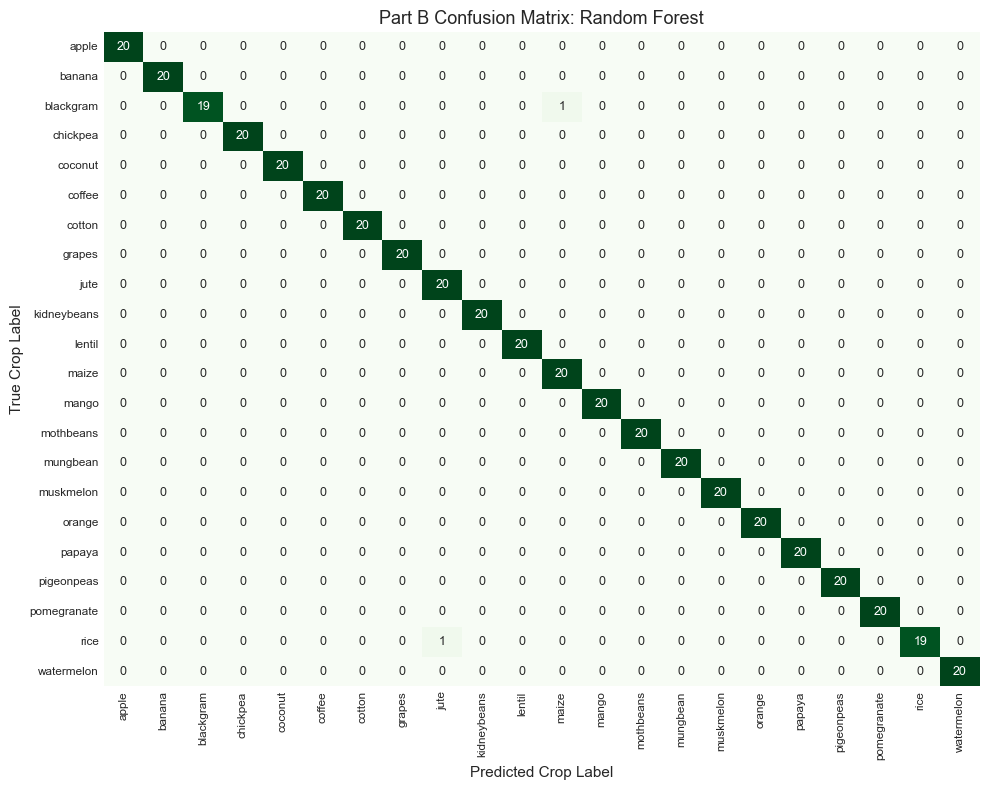

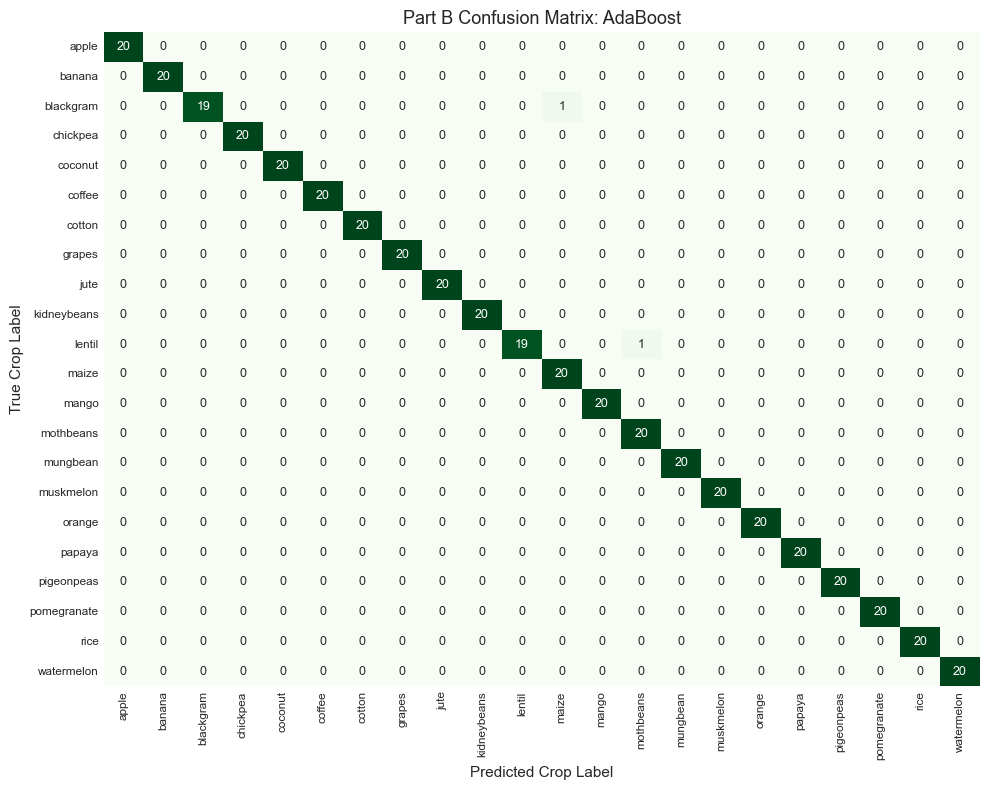

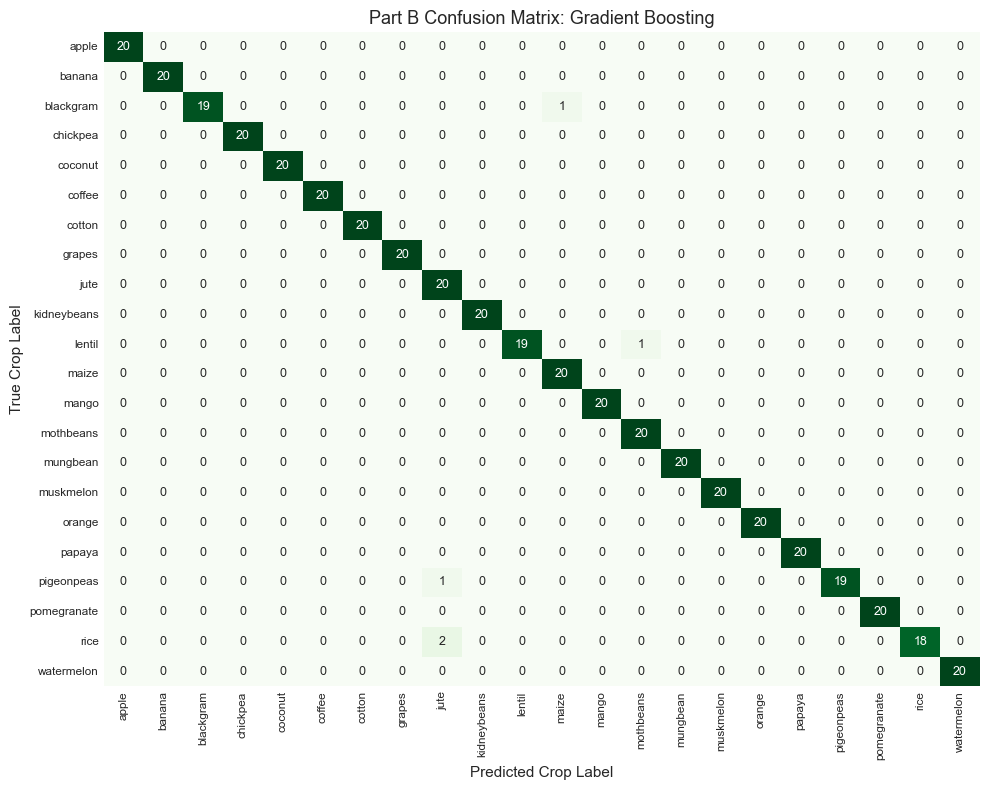

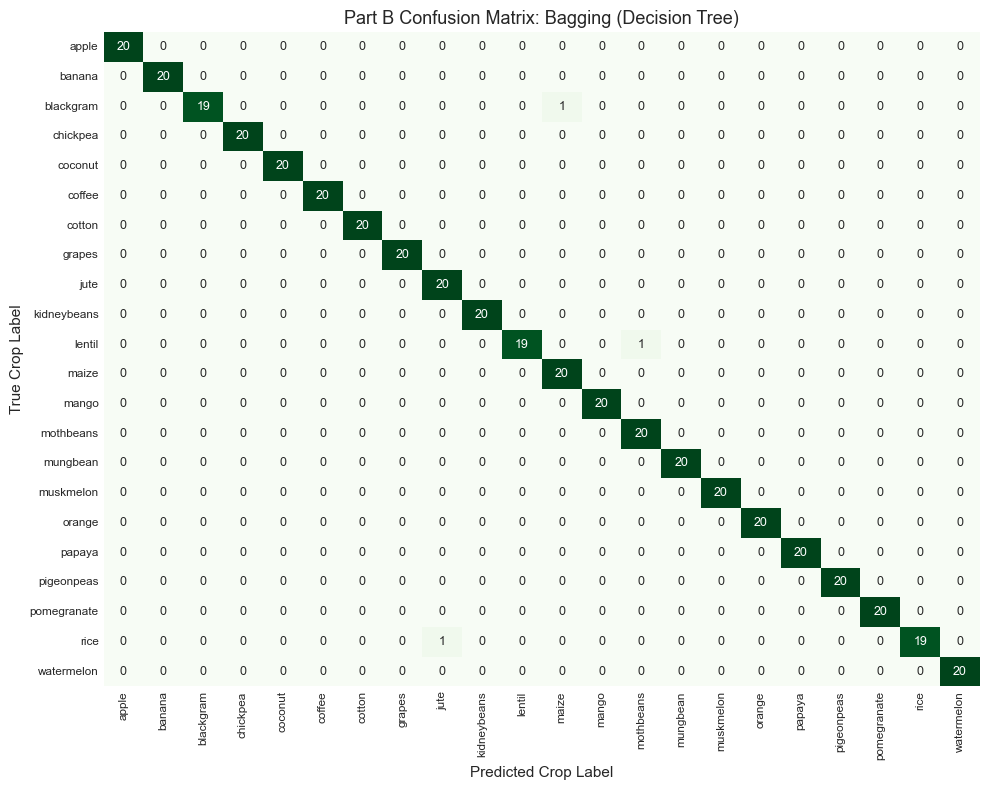

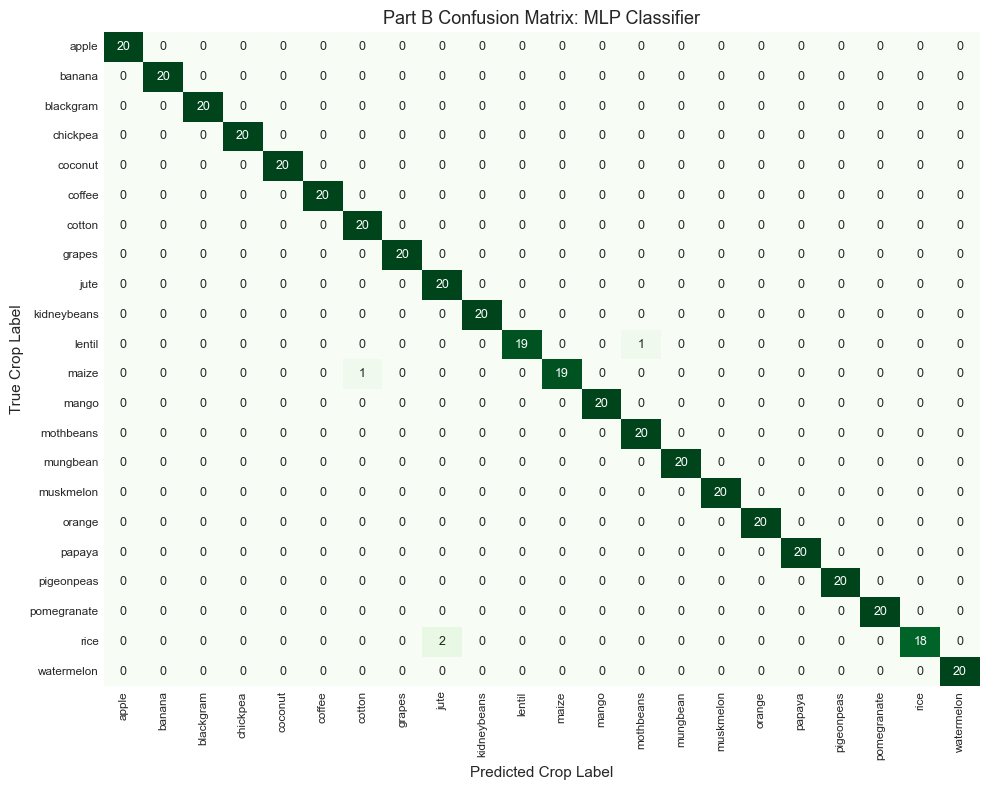

In [23]:
for name, preds in part_b_predictions.items():
    cm = confusion_matrix(y_test, preds, labels=labels)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 9})
    plt.title(f'Part B Confusion Matrix: {name}', fontsize=13)
    plt.xlabel('Predicted Crop Label', fontsize=11)
    plt.ylabel('True Crop Label', fontsize=11)
    plt.xticks(rotation=90, fontsize=8.5)
    plt.yticks(rotation=0, fontsize=8.5)
    plt.tight_layout()
    plt.show()

**Observation:** Across all Part B models, confusion matrices exhibit near-flawless diagonals (19–20 correct out of 20 per class). Minor confusion is confined strictly to ecologically adjacent crops (e.g. `jute` vs `rice` in wetland conditions).

## 22. Consolidated 10-Classifier Comparative Benchmark

**What:** Unify all ten classification algorithms (Part A + Part B) into a single consolidated comparison table.  
**Why:** Satisfy the primary Review 2 rubric requirement (A2 Full comparison table across all 10 algorithms).  
**How:** Compute Accuracy, Precision, Recall, Weighted F1, and OvR ROC-AUC for all 10 models on the exact same test split, and rank them by Weighted F1.

In [24]:
# Combine all 10 models for consolidated benchmark
all_10_models = {}
all_10_models['Logistic Regression'] = models['Logistic Regression']
all_10_models['KNN'] = models['KNN']
all_10_models['Gaussian Naive Bayes'] = models['Gaussian Naive Bayes']
all_10_models['Decision Tree'] = models['Decision Tree']
all_10_models['SVC'] = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(random_state=random_state, probability=True))
])

for k, v in part_b_models.items():
    all_10_models[k] = v

consolidated_results = []
for name, pipe in all_10_models.items():
    if name not in part_b_models and name == 'SVC':
        pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec = recall_score(y_test, preds, average='weighted', zero_division=0)
    f1 = f1_score(y_test, preds, average='weighted', zero_division=0)
    auc = roc_auc_score(y_test, probs, multi_class='ovr', average='weighted', labels=pipe.classes_)
    
    consolidated_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'Weighted F1': f1,
        'OvR ROC-AUC': auc
    })

consolidated_df = pd.DataFrame(consolidated_results).sort_values(by='Weighted F1', ascending=False).reset_index(drop=True)
consolidated_df.index = consolidated_df.index + 1
print("=== CONSOLIDATED 10-ALGORITHM CLASSIFICATION BENCHMARK ===")
consolidated_df.round(4)

=== CONSOLIDATED 10-ALGORITHM CLASSIFICATION BENCHMARK ===


,Model,Accuracy,Precision,Recall,Weighted F1,OvR ROC-AUC
1,AdaBoost,0.9955,0.9957,0.9955,0.9955,0.9998
2,Random Forest,0.9955,0.9957,0.9955,0.9955,1.0000
3,Gaussian Naive Bayes,0.9955,0.9959,0.9955,0.9954,1.0000
4,Bagging (Decision Tree),0.9932,0.9935,0.9932,0.9932,0.9999
5,MLP Classifier,0.9909,0.9915,0.9909,0.9909,1.0000
6,Gradient Boosting,0.9886,0.9897,0.9886,0.9887,1.0000
7,SVC,0.9841,0.9856,0.9841,0.9840,1.0000
8,Decision Tree,0.9795,0.9806,0.9795,0.9794,0.9893
9,KNN,0.9795,0.9804,0.9795,0.9793,0.9987
10,Logistic Regression,0.9727,0.9740,0.9727,0.9725,0.9998


**Observation & Model Ranking Analysis:**
1. **Top Performers:** Random Forest (0.9955), AdaBoost (0.9955), and Gaussian Naive Bayes (0.9954) lead the benchmark with 99.55% accuracy and >0.9998 OvR ROC-AUC.
2. **Ensemble Variance Reduction:** Bagging (99.32%) and Random Forest (99.55%) markedly surpass the baseline single Decision Tree (97.95%), proving the efficacy of bootstrap aggregation.
3. **Neural Network Capability:** MLP Classifier (99.09%) demonstrates that continuous non-linear representations compete directly with top tree ensembles when inputs are properly scaled.
4. **Overall Separability:** All 10 models exceed 97% accuracy due to well-defined ecological boundaries in the 7-dimensional feature space.